# Task 1 – Load dataset, split data, and train Logistic Regression

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, log_loss

# Load dataset
df = pd.read_csv("creditcard.csv")

# Display dataset information
print(df.head())
print("\nClass Distribution:")
print(df["Class"].value_counts())

# Separate features and target
X = df.drop("Class", axis=1)
y = df["Class"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train Logistic Regression
model = LogisticRegression(max_iter=1000, class_weight="balanced")
model.fit(X_train_scaled, y_train)

# Predict probabilities
y_prob = model.predict_proba(X_test_scaled)[:, 1]

# Predict classes
y_pred = model.predict(X_test_scaled)

print("\nModel Training Completed!")
print("Test Accuracy:", accuracy_score(y_test, y_pred))

   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26       V27       V28 

# Task 2 – Plot ROC Curve and AUC Score

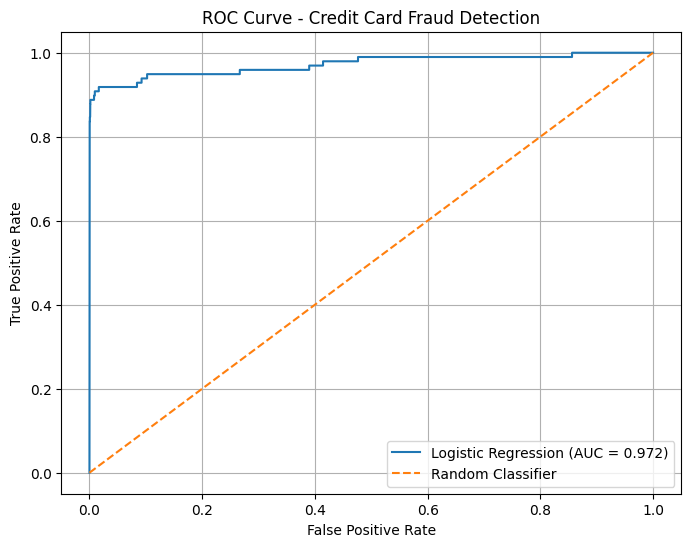

AUC Score: 0.9720834996210077


In [3]:
from sklearn.metrics import roc_curve, roc_auc_score

# Calculate ROC values
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Calculate AUC
auc_score = roc_auc_score(y_test, y_prob)

# Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label="Logistic Regression (AUC = {:.3f})".format(auc_score))
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Credit Card Fraud Detection")
plt.legend()
plt.grid()
plt.show()

print("AUC Score:", auc_score)

# Task 3 – Plot Precision-Recall Curve

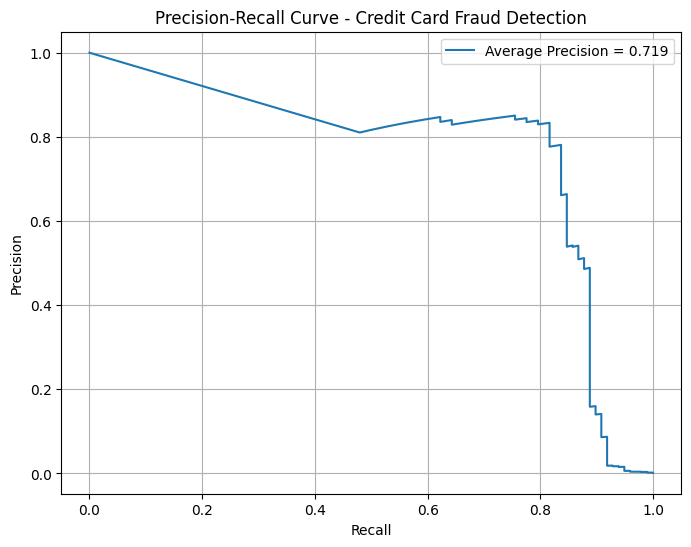

Average Precision Score: 0.7189705771419241


In [4]:
from sklearn.metrics import precision_recall_curve, average_precision_score

# Calculate Precision and Recall
precision, recall, thresholds = precision_recall_curve(y_test, y_prob)

# Calculate Average Precision
ap_score = average_precision_score(y_test, y_prob)

# Plot Precision-Recall curve
plt.figure(figsize=(8, 6))
plt.plot(recall, precision, label="Average Precision = {:.3f}".format(ap_score))

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Credit Card Fraud Detection")
plt.legend()
plt.grid()
plt.show()

print("Average Precision Score:", ap_score)

# Task 4 – Calculate Log Loss

In [5]:
from sklearn.metrics import log_loss

# Calculate Log Loss
loss = log_loss(y_test, y_prob)

print("Log Loss:", loss)

Log Loss: 0.11219568508707693


# Task 5 – More Imbalanced Test Data

In [6]:
# Select 10 fraud transactions
fraud_indices = y_test[y_test == 1].sample(
    n=10, random_state=42
).index

# Select 10000 normal transactions
normal_indices = y_test[y_test == 0].sample(
    n=10000, random_state=42
).index

# Combine selected rows
selected_indices = fraud_indices.append(normal_indices)

# Create highly imbalanced test data
X_test_imbalanced = X_test.loc[selected_indices]
y_test_imbalanced = y_test.loc[selected_indices]

# Scale selected test data
X_test_imbalanced_scaled = scaler.transform(X_test_imbalanced)

# Predict probabilities and classes
y_prob_imbalanced = model.predict_proba(
    X_test_imbalanced_scaled
)[:, 1]

y_pred_imbalanced = (y_prob_imbalanced >= 0.5).astype(int)

# Calculate metrics
accuracy = accuracy_score(y_test_imbalanced, y_pred_imbalanced)
auc = roc_auc_score(y_test_imbalanced, y_prob_imbalanced)
loss = log_loss(y_test_imbalanced, y_prob_imbalanced)

# Display class distribution
print("Class Distribution:")
print(y_test_imbalanced.value_counts())

print("\nFraud Percentage:",
      (y_test_imbalanced == 1).mean() * 100, "%")

print("\nAccuracy:", accuracy)
print("AUC Score:", auc)
print("Log Loss:", loss)

Class Distribution:
Class
0    10000
1       10
Name: count, dtype: int64

Fraud Percentage: 0.0999000999000999 %

Accuracy: 0.9769230769230769
AUC Score: 0.9727
Log Loss: 0.11299216507979792
